<a href="https://colab.research.google.com/github/peter-adepoju/math-neuro-ml/blob/main/project/Project6_Starter.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **MAMBA Project Week — Option 6: How Do Action Potentials Change During a Train?**

**Question.** Within a train of action potentials driven by a current step, how do threshold, height, rate of rise and width change from spike to spike?

**Minimum result.** For every spike in both cells: threshold (where dV/dt first exceeds 20 mV/ms), peak, peak dV/dt and width at half height, plotted against the spike's position in its train, with a bootstrap interval for the first-versus-later difference in threshold.

**Lessons to revisit.** 9 (derivatives, finite differences), 13 (sampling), 17 and 20 (variability, bootstrap).

**Data.** `patch_18711001_ap20k.npz` and `patch_171116sh_0018_ap20k.npz`. Whole-cell current-clamp sample recordings distributed with pyABF (S. W. Harden; MIT licence). The cell type and preparation are not documented.

**How to use this notebook.** Run it top to bottom: it loads the data, shows it, and works one first step for you. Cells marked `# TODO` are yours; each is followed by a check cell that prints *TODO* until your code sets the variables it names, then tests their shapes and simple sanity conditions. Add your own cells freely, but keep every array described by its shape and units.

### Set-up

In [1]:
# SETUP -- run first.
import os, urllib.request
import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(42)
PALETTE = ['#0072B2', '#D55E00', '#009E73', '#CC79A7', '#E69F00', '#56B4E9']   # Okabe-Ito, as in the lessons
plt.rcParams.update({'axes.spines.top': False, 'axes.spines.right': False, 'axes.grid': False, 'figure.dpi': 100})
DATA_URL = 'https://raw.githubusercontent.com/peter-adepoju/math-neuro-ml/51d88220064023b5d3240c39e19b07acc7896f44/data/'

def load(name):
    # A local copy (here, or in the repository's data/ folder) first; otherwise download it from the pinned commit.
    for candidate in [name, os.path.join('..', 'data', name), os.path.join('..', '..', 'data', name)]:
        if os.path.exists(candidate):
            return np.load(candidate)
    urllib.request.urlretrieve(DATA_URL + name, name)
    return np.load(name)

def todo(*values):
    # True while any of the values is still None: the check cells below use it to wait for your code.
    return any(v is None for v in values)
print('Set-up complete.')

Set-up complete.


### Data tour

| Array | Shape | Meaning, units |
|---|---|---|
| `V[c]` | (sweeps, 11000) | membrane potential of cell `c` (mV), 20 kHz, during depolarising steps |
| `I[c]` | (sweeps,) | step current (pA) |
| `dt` | scalar | 0.05 ms |

cell A: V (29, 11000) mV, steps 10-290 pA
cell B: V (12, 11000) mV, steps 25-300 pA


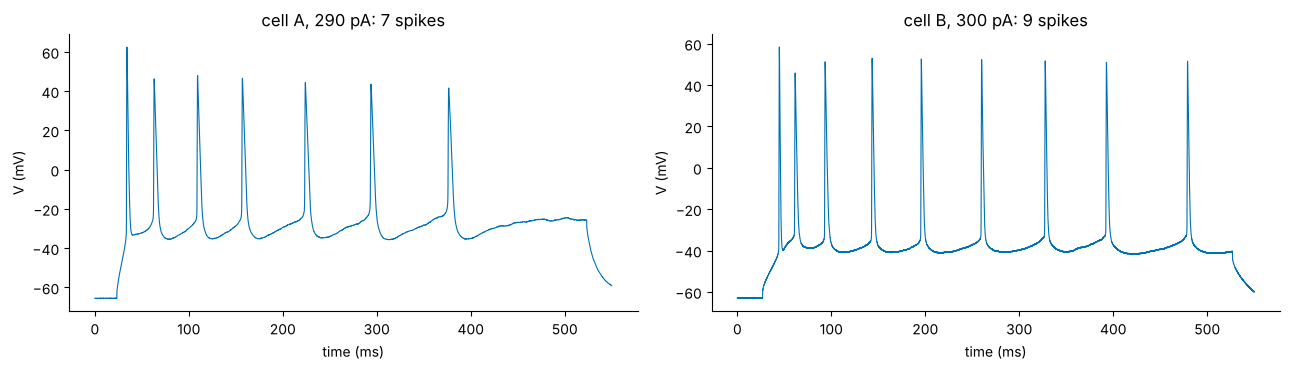

In [2]:
from scipy.signal import find_peaks
cells = {'A': 'patch_18711001_ap20k.npz', 'B': 'patch_171116sh_0018_ap20k.npz'}
V, I = {}, {}
for c, f in cells.items():
    dd = load(f); V[c] = dd['v_cmV'] / 100; I[c] = dd['step_pA']
    print(f"cell {c}: V {V[c].shape} mV, steps {I[c].min():.0f}-{I[c].max():.0f} pA")
dt = 0.05
spikes = {c: [find_peaks(v, height=0, distance=40)[0] for v in V[c]] for c in cells}
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
for ax, c in zip(axes, cells):
    s = len(V[c]) - 1
    ax.plot(np.arange(V[c].shape[1]) * dt, V[c][s], color=PALETTE[0], lw=0.8)
    ax.set_xlabel('time (ms)'); ax.set_ylabel('V (mV)'); ax.set_title(f'cell {c}, {I[c][s]:.0f} pA: {len(spikes[c][s])} spikes')
plt.tight_layout(); plt.show()

### Worked first step: threshold and peak dV/dt of one spike

In [3]:
def dvdt(v):
    return np.gradient(v, dt)                                # mV/ms, central differences
c, s = 'A', len(V['A']) - 1
v = V[c][s]; p = spikes[c][s][0]; dv = dvdt(v)
seg = dv[p - 40:p + 1]
thr_idx = p - 40 + np.argmax(seg > 20)
print(f"cell {c}, sweep {s}, first spike: threshold {v[thr_idx]:.1f} mV, peak {v[p]:.1f} mV, peak dV/dt {seg.max():.0f} mV/ms")

cell A, sweep 28, first spike: threshold -31.8 mV, peak 62.5 mV, peak dV/dt 344 mV/ms


In [4]:
# TODO 1 -- Features of every spike. Build a dict feats with keys 'cell', 'current', 'order' (0 = first spike of its
# sweep), 'thr' (mV), 'peak' (mV), 'maxdv' (mV/ms) and 'width' (ms: time above the half-height (thr + peak) / 2 around
# the peak), each a NumPy array with one entry per spike, over both cells and all sweeps.
feats = None

In [5]:
if todo(feats):
    print('TODO 1 not done yet.')
else:
    n = len(feats['thr']); assert all(len(a) == n for a in feats.values())
    assert np.all(feats['peak'] > feats['thr']) and np.all(feats['width'] > 0)
    print('Check 1 passed.')

TODO 1 not done yet.


In [6]:
# TODO 2 -- Plot threshold, peak dV/dt and width against spike order for each cell. Then, for each cell, store in
# diff_ci[c] = (difference, low, high): the mean threshold of later spikes minus that of first spikes, with a 95%
# bootstrap interval (resample spikes within each group, 2000 times).
diff_ci = None

In [7]:
if todo(diff_ci):
    print('TODO 2 not done yet.')
else:
    assert all(v[1] <= v[0] <= v[2] for v in diff_ci.values())
    print('Check 2 passed.')

TODO 2 not done yet.


In [8]:
# TODO 3 -- Sampling rate. Keep every 2nd and every 4th sample (10 and 5 kHz), recompute the mean peak dV/dt over all
# spikes of cell A with np.gradient at the new spacing, and store peak_by_rate = {20: ..., 10: ..., 5: ...} (mV/ms).
peak_by_rate = None

In [9]:
if todo(peak_by_rate):
    print('TODO 3 not done yet.')
else:
    assert peak_by_rate[20] >= peak_by_rate[10] >= peak_by_rate[5] * 0.9, "coarser sampling blunts the upstroke"
    print('Check 3 passed.')

TODO 3 not done yet.


### Before the talk
- State the threshold definition (20 mV/ms) and the step; Lesson 9 showed that both change the answer.
- Two cells of unknown type: describe, do not generalise.
- Spikes in a train differ in order **and** in the time since the previous spike: try to separate the two.